# Netflix Release Year Trend Analysis

## Project Overview
This project analyzes Netflix content release trends using Python. It explores yearly content distribution and compares Movies and TV Shows across different release years.

## Project Objectives
- Analyze Netflix content releases by year.
- Identify years with the highest and lowest content releases.
- Compare Movies and TV Shows release trends.
- Identify top 10 years by content releases.
- Create visualizations and meaningful insights.

## 1. Import Required Libraries

The required Python libraries are imported for data analysis and visualization.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Loading the Dataset

The cleaned Netflix dataset is loaded using Pandas for further analysis.

In [2]:
df = pd.read_csv("data/Netflix_Cleaned.csv")

df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


## Dataset Information

- **Dataset:** Netflix Cleaned Dataset
- **Total Records:** 8,790
- **Total Columns:** 10
- **Release Years Analyzed:** 74
- **Missing Values:** 0
- **Duplicate Records:** 0

## 3. Initial Data Inspection

The dataset is inspected to understand its structure, data types, and missing values.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.8+ KB


## 4. Release Year Analysis

The number of Netflix titles released in each year is calculated to identify content distribution patterns.

In [4]:
year_counts = df['release_year'].value_counts().sort_index()

year_counts

release_year
1925       1
1942       2
1943       3
1944       3
1945       4
        ... 
2017    1030
2018    1146
2019    1030
2020     953
2021     592
Name: count, Length: 74, dtype: int64

In [5]:
print("Year with Highest Content:")
print(year_counts.idxmax(), "-", year_counts.max(), "titles")

print("\nYear with Lowest Content:")
print(year_counts.idxmin(), "-", year_counts.min(), "titles")

Year with Highest Content:
2018 - 1146 titles

Year with Lowest Content:
1925 - 1 titles


## 5. Release Year Trend Visualization

A line chart is created to visualize the overall trend of Netflix content releases across different years.

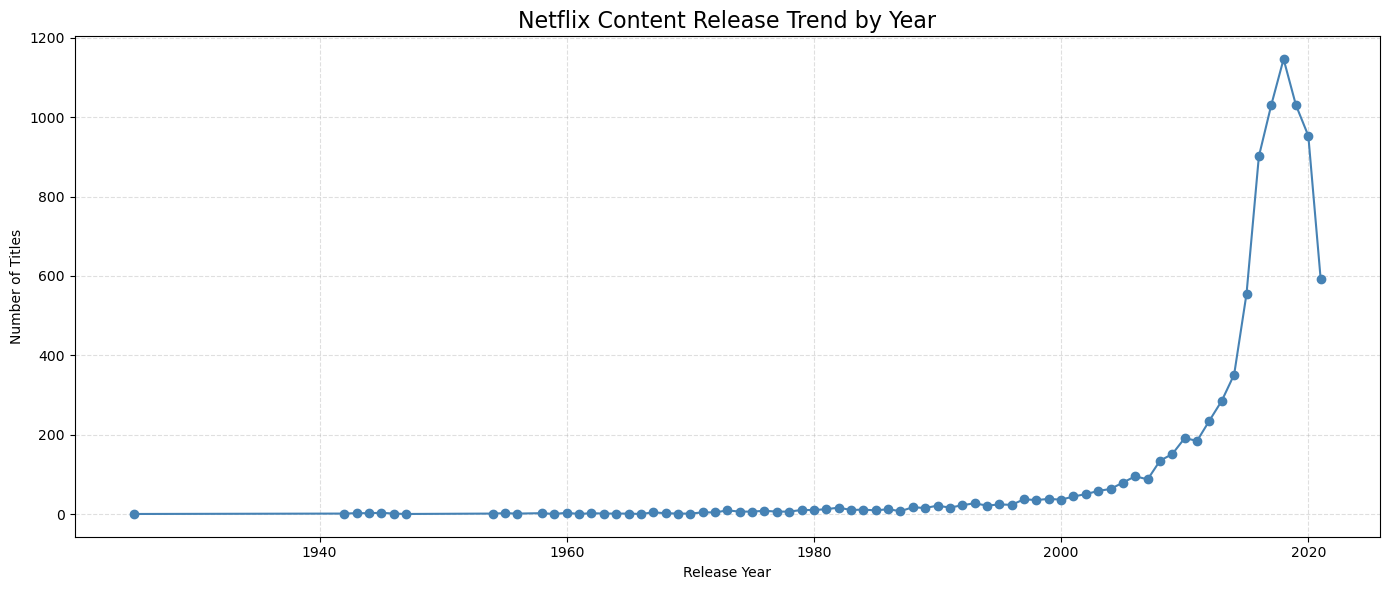

In [6]:
plt.figure(figsize=(14, 6))

year_counts.plot(kind='line', marker='o', color='steelblue')

plt.title("Netflix Content Release Trend by Year", fontsize=16)
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

## 6. Movies vs TV Shows Analysis

The yearly distribution of Movies and TV Shows is calculated to compare their release patterns.

In [7]:
year_type = pd.crosstab(
    df['release_year'],
    df['type']
)

year_type

type,Movie,TV Show
release_year,,
1925,0,1
1942,2,0
1943,3,0
1944,3,0
1945,3,1
...,...,...
2017,765,265
2018,767,379
2019,633,397


## 7. Movies vs TV Shows Trend Visualization

A line chart is used to compare yearly release trends of Movies and TV Shows.

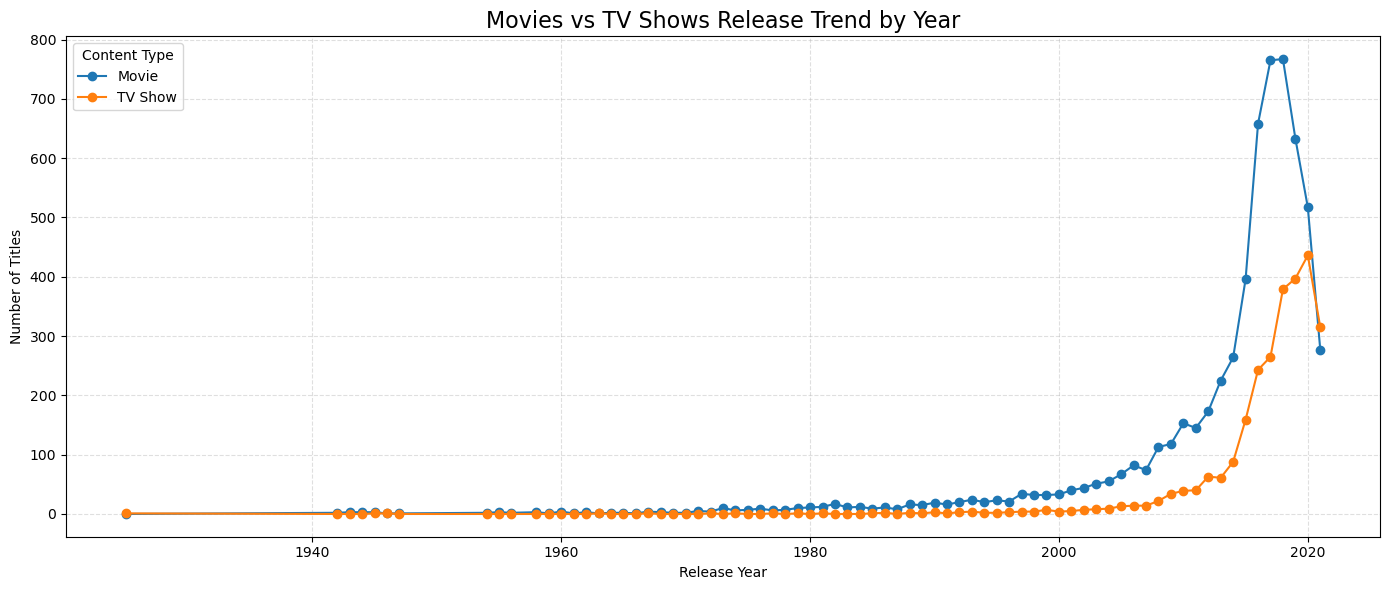

In [8]:
year_type.plot(
    kind='line',
    figsize=(14, 6),
    marker='o'
)

plt.title("Movies vs TV Shows Release Trend by Year", fontsize=16)
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.legend(title="Content Type")
plt.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

In [9]:
top_10_years = year_counts.sort_values(ascending=False).head(10)

top_10_years

release_year
2018    1146
2019    1030
2017    1030
2020     953
2016     901
2021     592
2015     555
2014     352
2013     286
2012     236
Name: count, dtype: int64

## 9. Top 10 Years Visualization

A horizontal bar chart is created to visualize the top 10 years with the highest Netflix content releases.

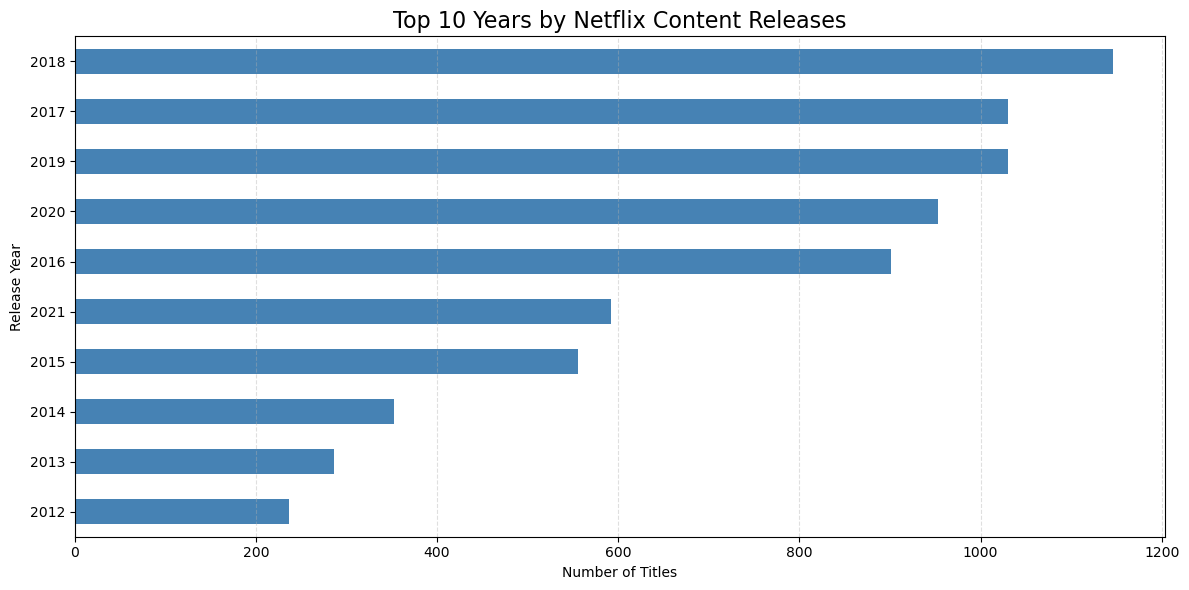

In [10]:
plt.figure(figsize=(12, 6))

top_10_years.sort_values().plot(
    kind='barh',
    color='steelblue'
)

plt.title("Top 10 Years by Netflix Content Releases", fontsize=16)
plt.xlabel("Number of Titles")
plt.ylabel("Release Year")
plt.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

## 10. Highest Release Years Analysis

The years with the highest number of Movie and TV Show releases are identified separately to understand their peak release periods.

In [11]:
top_movie_year = year_type['Movie'].idxmax()
top_tv_year = year_type['TV Show'].idxmax()

print("Year with Highest Movie Releases:")
print(top_movie_year, "-", year_type['Movie'].max(), "Movies")

print("\nYear with Highest TV Show Releases:")
print(top_tv_year, "-", year_type['TV Show'].max(), "TV Shows")

Year with Highest Movie Releases:
2018 - 767 Movies

Year with Highest TV Show Releases:
2020 - 436 TV Shows


## 11. Year-Wise Summary Analysis

A summary table is created to compare yearly Movies and TV Shows releases, including their percentage distribution.

In [12]:
year_summary = pd.DataFrame({
    'Total Titles': year_counts,
    'Movies': year_type['Movie'],
    'TV Shows': year_type['TV Show']
})

year_summary['Movie Percentage'] = (
    year_summary['Movies'] / year_summary['Total Titles'] * 100
)

year_summary['TV Show Percentage'] = (
    year_summary['TV Shows'] / year_summary['Total Titles'] * 100
)

year_summary.sort_values(
    by='Total Titles',
    ascending=False
).head(10).round(2)

,Total Titles,Movies,TV Shows,Movie Percentage,TV Show Percentage
release_year,,,,,
2018,1146,767,379,66.93,33.07
2019,1030,633,397,61.46,38.54
2017,1030,765,265,74.27,25.73
2020,953,517,436,54.25,45.75
2016,901,658,243,73.03,26.97
2021,592,277,315,46.79,53.21
2015,555,396,159,71.35,28.65
2014,352,264,88,75.00,25.00
2013,286,225,61,78.67,21.33


In [13]:
year_summary.to_csv("output/Release_Year_Summary.csv")

print("Release Year Summary exported successfully!")

Release Year Summary exported successfully!


## 12. Final Data Validation

The dataset and analysis results are validated by checking the dataset shape, missing values, duplicate records, and total release years.

In [14]:
print("Dataset Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())
print("Total Release Years:", year_counts.shape[0])
print("Summary Records:", year_summary.shape[0])

Dataset Shape: (8790, 10)
Missing Values: 0
Duplicate Rows: 0
Total Release Years: 74
Summary Records: 74


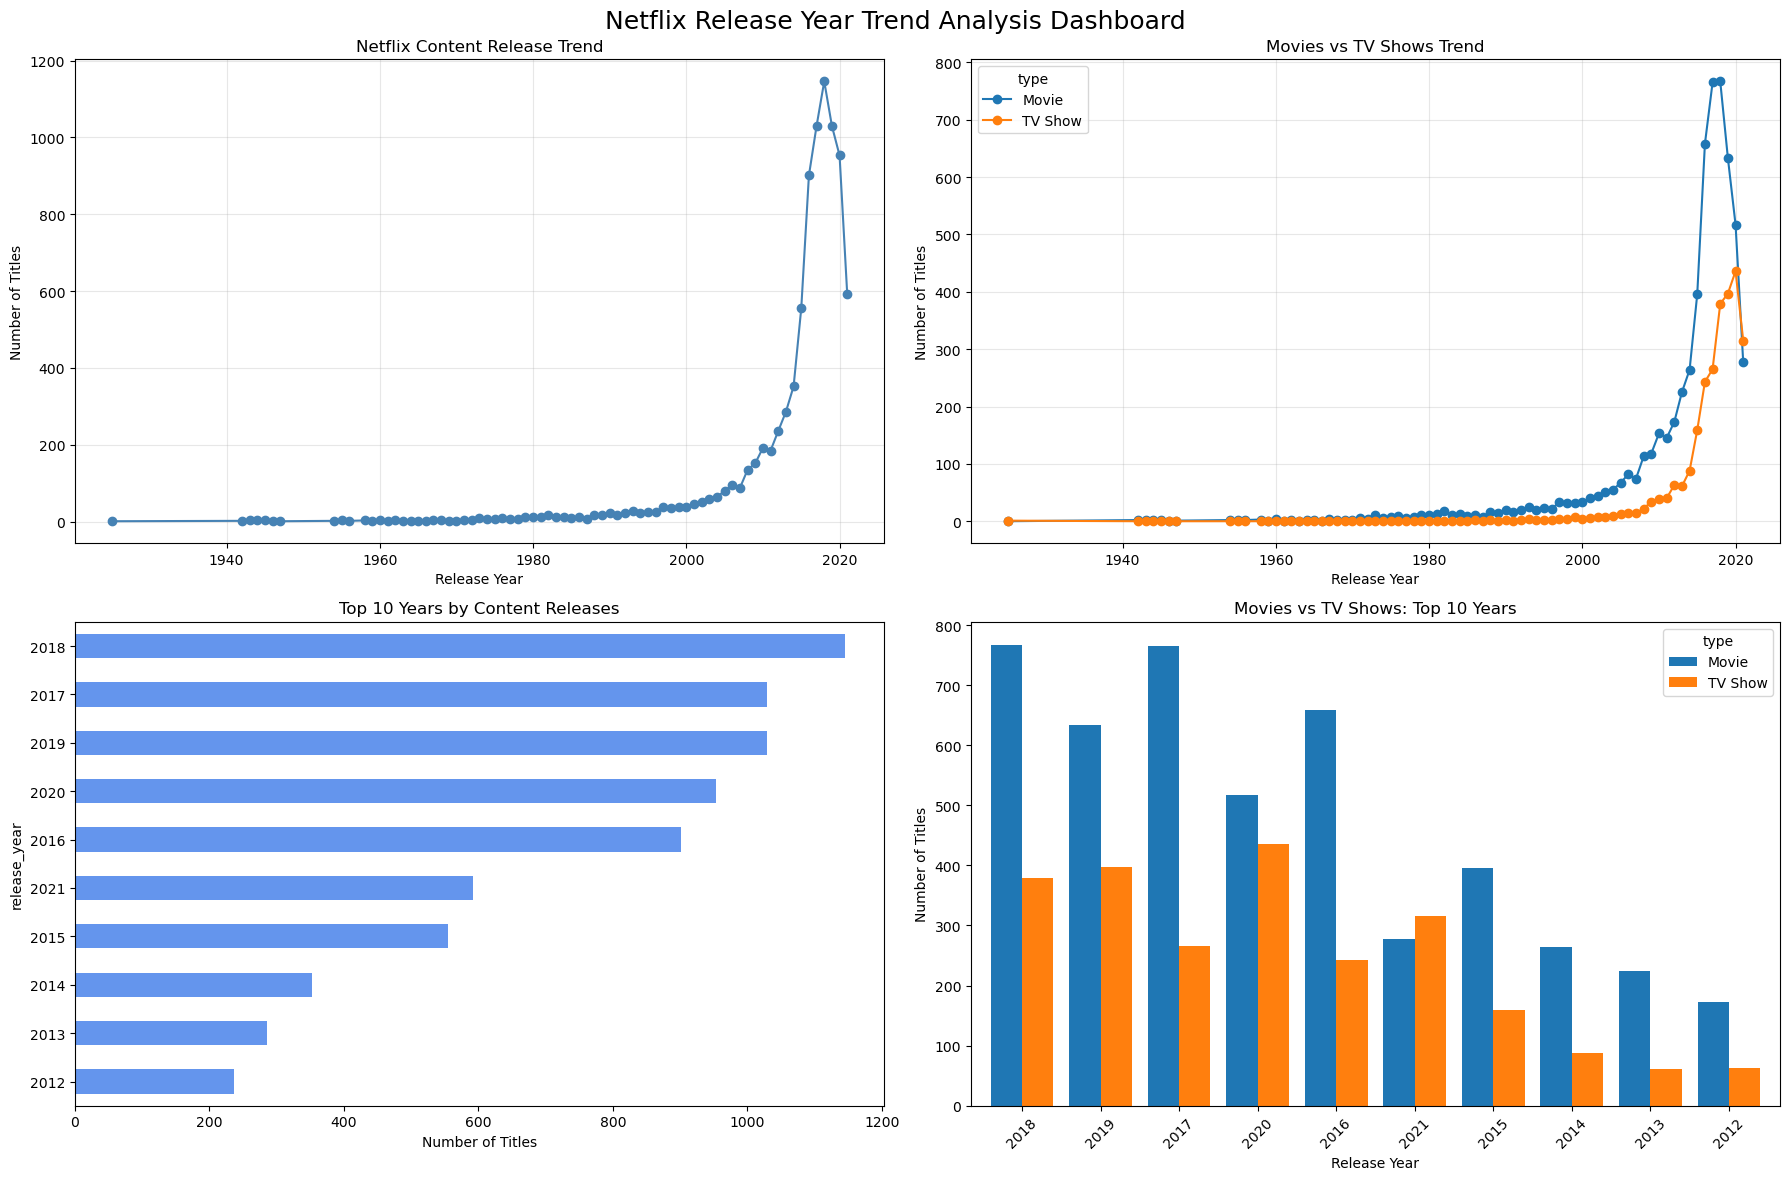

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# 1. Overall Release Year Trend
year_counts.plot(
    kind='line',
    marker='o',
    ax=axes[0, 0],
    color='steelblue'
)
axes[0, 0].set_title("Netflix Content Release Trend")
axes[0, 0].set_xlabel("Release Year")
axes[0, 0].set_ylabel("Number of Titles")
axes[0, 0].grid(True, alpha=0.3)

# 2. Movies vs TV Shows Trend
year_type.plot(
    kind='line',
    marker='o',
    ax=axes[0, 1]
)
axes[0, 1].set_title("Movies vs TV Shows Trend")
axes[0, 1].set_xlabel("Release Year")
axes[0, 1].set_ylabel("Number of Titles")
axes[0, 1].grid(True, alpha=0.3)

# 3. Top 10 Years
top_10_years.sort_values().plot(
    kind='barh',
    ax=axes[1, 0],
    color='cornflowerblue'
)
axes[1, 0].set_title("Top 10 Years by Content Releases")
axes[1, 0].set_xlabel("Number of Titles")

# 4. Top 10 Years Movies vs TV Shows
year_type.loc[top_10_years.index].plot(
    kind='bar',
    ax=axes[1, 1],
    width=0.8
)
axes[1, 1].set_title("Movies vs TV Shows: Top 10 Years")
axes[1, 1].set_xlabel("Release Year")
axes[1, 1].set_ylabel("Number of Titles")
axes[1, 1].tick_params(axis='x', rotation=45)

fig.suptitle(
    "Netflix Release Year Trend Analysis Dashboard",
    fontsize=18
)

plt.tight_layout()

plt.savefig(
    "output/Release_Year_Dashboard.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

## 13. Key Findings and Conclusion

### Key Findings
- The year 2018 recorded the highest number of Netflix content releases with 1,146 titles.
- The year 1925 recorded the lowest number of releases with only 1 title.
- Movies reached their highest release count in 2018 with 767 titles.
- TV Shows reached their highest release count in 2020 with 436 titles.
- In 2021, TV Shows accounted for 53.21% of total releases.

### Conclusion
This project analyzes Netflix content release trends using Python. It compares Movies and TV Shows across different years and identifies important release patterns through data analysis and visualization.